In [1]:
## Load Spotify and Genius datasets and inspect their dimensions and columns.

import pandas as pd
import matplotlib.pyplot as plt

# Load the outputs from Part 1 and Part 2
spotify_df = pd.read_csv("../data/spotify_tracks.csv")
genius_df = pd.read_csv("../data/genius_lyrics.csv")
print(spotify_df.shape, genius_df.shape)
print(spotify_df.columns.tolist())
print(genius_df.columns.tolist())

(94, 7) (93, 7)
['Album', 'Song Name', 'Track Number', 'Duration (s)', 'Explicit', 'Release Date', 'Track ID']
['Album', 'Song Name', 'Lyrics', 'Genius URL', 'Album Release Date', 'Annotation Count', 'Spotify Song Name']


In [2]:
## Standardize column names by removing spaces, converting to lowercase, and replacing spaces with underscores.
def standardize(cols):
    return (cols.str.strip()
                .str.lower()
                .str.replace(r"[()]", "", regex=True)  # "Duration (s)" -> "duration s"
                .str.replace(r"\s+", "_", regex=True))  # spaces -> _

spotify_df.columns = standardize(spotify_df.columns)
genius_df.columns = standardize(genius_df.columns)
print(spotify_df.columns.tolist())
print(genius_df.columns.tolist())

['album', 'song_name', 'track_number', 'duration_s', 'explicit', 'release_date', 'track_id']
['album', 'song_name', 'lyrics', 'genius_url', 'album_release_date', 'annotation_count', 'spotify_song_name']


In [3]:
## Identify song and album name mismatches between Spotify and Genius and evaluate naive merge results.

# Bring the Spotify album into the Genius table (via the Spotify title we searched with)
check = genius_df.merge(spotify_df[["song_name", "album"]],
                        left_on="spotify_song_name", right_on="song_name",
                        suffixes=("_genius", "_spotify"))

# Song names that differ between the two sources
song_mismatch = check[check["song_name_genius"] != check["song_name_spotify"]]
print("Song name mismatches:", len(song_mismatch))
display(song_mismatch[["song_name_spotify", "song_name_genius"]])

# Album names that differ between the two sources
album_mismatch = check[check["album_genius"] != check["album_spotify"]]
print("Album mismatches:", len(album_mismatch))
display(album_mismatch[["song_name_spotify", "album_spotify", "album_genius"]])

# Merge naively (without fixing anything)
naive = spotify_df.merge(genius_df, on=["album", "song_name"], how="inner")
print("Naive merge matched:", len(naive), "of", len(spotify_df))

Song name mismatches: 18


,song_name_spotify,song_name_genius
4,Belong To The World,Belong To the World
16,Can't Feel My Face,Can’t Feel My Face
18,Earned It (Fifty Shades Of Grey),Earned It
19,In The Night,In the Night
34,Love To Lay,Love to Lay
63,"Here We Go… Again (feat. Tyler, the Creator)",Here We Go... Again
69,I Heard You’re Married (feat. Lil Wayne),I Heard You’re Married
72,Wake Me Up (feat. Justice),Wake Me Up
74,I Can't Fucking Sing,I Can’t Fucking Sing
75,São Paulo (feat. Anitta),São Paulo


Album mismatches: 26


,song_name_spotify,album_spotify,album_genius
0,Professional,Kiss Land,Kiss Land
1,The Town,Kiss Land,Kiss Land
2,Adaptation,Kiss Land,Kiss Land
3,Love In The Sky,Kiss Land,Kiss Land
4,Belong To The World,Kiss Land,Kiss Land
5,Live For,Kiss Land,Kiss Land
6,Wanderlust,Kiss Land,Kiss Land
7,Kiss Land,Kiss Land,Kiss Land
8,Pretty,Kiss Land,Kiss Land
9,Tears In The Rain,Kiss Land,Kiss Land


Naive merge matched: 54 of 94


In [4]:
## Standardize song and album names using Spotify data, then merge with Genius while keeping all Spotify songs.

# Keep the original Genius names for reference
genius_df = genius_df.rename(columns={"song_name": "genius_song_name",
                                      "album": "genius_album"})

# Use the Spotify title as the standard song name
genius_df["song_name"] = genius_df["spotify_song_name"]

# Use the Spotify album as the standard album name
album_lookup = spotify_df.set_index("song_name")["album"]
genius_df["album"] = genius_df["song_name"].map(album_lookup)

# Merge: keep all Spotify songs, add Genius fields where available
combined = spotify_df.merge(
    genius_df.drop(columns=["spotify_song_name"]),
    on=["album", "song_name"],
    how="left",
    indicator=True  # adds a "_merge" column showing where each row came from
)

print(combined["_merge"].value_counts())

_merge
both          93
left_only      1
right_only     0
Name: count, dtype: int64


In [5]:
# Export the final combined dataset
combined = combined.drop(columns="_merge")
combined.to_csv("../data/combined_tracks.csv", index=False)
print(combined.shape)
combined.head()

(94, 13)


,album,song_name,track_number,duration_s,explicit,release_date,track_id,genius_album,genius_song_name,lyrics,genius_url,album_release_date,annotation_count
0,Kiss Land,Professional,1,368.7,False,2013-01-01,2gOEWbtEzHtpHb9fywSEiw,Kiss Land,Professional,"It's ideal, oh\nYou need someone to tell you h...",https://genius.com/The-weeknd-professional-lyrics,"September 10, 2013",14.0
1,Kiss Land,The Town,2,307.3,False,2013-01-01,3RB6zxrgPQBUxpTtoMW60r,Kiss Land,The Town,"You did many things\nThat I liked, that I like...",https://genius.com/The-weeknd-the-town-lyrics,"September 10, 2013",8.0
2,Kiss Land,Adaptation,3,283.9,False,2013-01-01,31ue6kAOfrqVrdoPdfkq40,Kiss Land,Adaptation,"When the sun comes up, you're searching for a ...",https://genius.com/The-weeknd-adaptation-lyrics,"September 10, 2013",12.0
3,Kiss Land,Love In The Sky,4,267.9,True,2013-01-01,7fSKE9J3udo8zpq1ceYTEa,Kiss Land,Love In The Sky,"There's no one inside, uh\nBut you're free to ...",https://genius.com/The-weeknd-love-in-the-sky-...,"September 10, 2013",20.0
4,Kiss Land,Belong To The World,5,307.2,False,2013-01-01,2jst5B18Q3PN3rwwIfnAgp,Kiss Land,Belong To the World,The wind in the sky\nPlease gather the clouds\...,https://genius.com/The-weeknd-belong-to-the-wo...,"September 10, 2013",12.0


In [6]:
## Summarize track counts, durations, and explicit content percentages by album.

# Summarize Spotify data per album, ordered by release date
album_summary = (combined.groupby("album")
                 .agg(release_date=("release_date", "first"),
                      n_tracks=("song_name", "count"),
                      avg_duration_s=("duration_s", "mean"),
                      median_duration_s=("duration_s", "median"),
                      pct_explicit=("explicit", "mean"))
                 .sort_values("release_date"))
album_summary["avg_duration_min"] = (album_summary["avg_duration_s"] / 60).round(2)
album_summary["pct_explicit"] = (album_summary["pct_explicit"] * 100).round(1)
album_summary

,release_date,n_tracks,avg_duration_s,median_duration_s,pct_explicit,avg_duration_min
album,,,,,,
Kiss Land,2013-01-01,10,333.990000,307.25,40.0,5.57
Beauty Behind The Madness,2015-08-28,14,279.485714,267.80,92.9,4.66
Starboy,2016-11-25,18,228.683333,226.90,44.4,3.81
After Hours,2020-03-20,14,241.257143,226.55,85.7,4.02
Dawn FM,2022-01-06,16,194.318750,202.30,25.0,3.24
Hurry Up Tomorrow,2025-01-31,22,231.322727,244.30,36.4,3.86


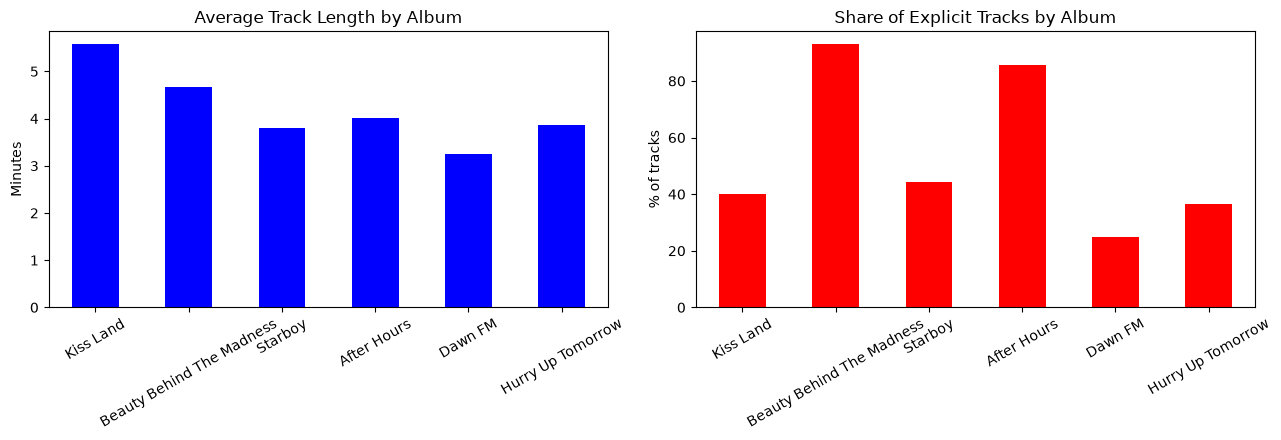

In [7]:
# Plot average track length and share of explicit tracks per album
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

album_summary["avg_duration_min"].plot.bar(ax=axes[0], color="blue")
axes[0].set_title("Average Track Length by Album")
axes[0].set_ylabel("Minutes")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

album_summary["pct_explicit"].plot.bar(ax=axes[1], color="red")
axes[1].set_title("Share of Explicit Tracks by Album")
axes[1].set_ylabel("% of tracks")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

The Weeknd's average track length generally decreased over time, from 5.57 minutes in Kiss Land to 3.24 minutes in Dawn FM, with a slight increase in Hurry Up Tomorrow. The share of explicit tracks varies across albums, peaking in Beauty Behind The Madness and reaching its lowest point in Dawn FM.

In [8]:
## Analyze lyrics by album, including word count, vocabulary diversity, word density, and annotations.

# Create lyric-based features
combined["lyrics"] = combined["lyrics"].fillna("")
combined["word_count"] = combined["lyrics"].str.split().str.len()

# Vocabulary diversity: unique words / total words
def unique_ratio(text):
    words = text.lower().split()
    return len(set(words)) / len(words) if words else None
combined["unique_word_ratio"] = combined["lyrics"].apply(unique_ratio)

# Words per second
combined["words_per_sec"] = combined["word_count"] / combined["duration_s"]

lyrics_summary = (combined[combined["word_count"] > 0]
                  .groupby("album")
                  .agg(release_date=("release_date", "first"),
                       avg_word_count=("word_count", "mean"),
                       avg_unique_ratio=("unique_word_ratio", "mean"),
                       avg_words_per_sec=("words_per_sec", "mean"),
                       avg_annotations=("annotation_count", "mean"))
                  .sort_values("release_date")
                  .round(2))
lyrics_summary

,release_date,avg_word_count,avg_unique_ratio,avg_words_per_sec,avg_annotations
album,,,,,
Kiss Land,2013-01-01,480.10,0.37,1.46,15.80
Beauty Behind The Madness,2015-08-28,425.79,0.30,1.55,9.50
Starboy,2016-11-25,411.56,0.32,1.77,10.22
After Hours,2020-03-20,316.00,0.40,1.31,12.57
Dawn FM,2022-01-06,287.62,0.46,1.50,15.31
Hurry Up Tomorrow,2025-01-31,312.71,0.45,1.33,13.86


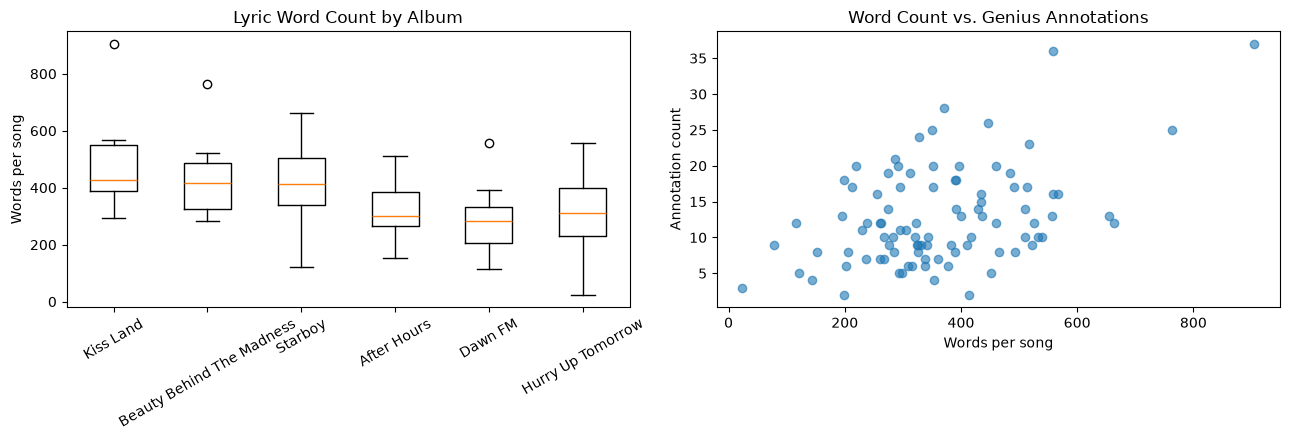

Correlation (word count vs annotations): 0.44


In [9]:
## Visualize lyric lengths by album and examine their correlation with Genius annotations.

# Left: lyric length by album; Right: does lyric length relate to how much it's annotated?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = lyrics_summary.index.tolist()
data = [combined.loc[(combined["album"] == a) & (combined["word_count"] > 0), "word_count"]
        for a in order]
axes[0].boxplot(data, tick_labels=order)
axes[0].set_title("Lyric Word Count by Album")
axes[0].set_ylabel("Words per song")
axes[0].tick_params(axis="x", rotation=30)

d = combined[combined["word_count"] > 0]
axes[1].scatter(d["word_count"], d["annotation_count"], alpha=0.6)
axes[1].set_title("Word Count vs. Genius Annotations")
axes[1].set_xlabel("Words per song")
axes[1].set_ylabel("Annotation count")

plt.tight_layout()
plt.show()

print("Correlation (word count vs annotations):",
      round(d["word_count"].corr(d["annotation_count"]), 2))

The Weeknd's average lyric word count generally decreased over time, from 480 words in Kiss Land to 288 in Dawn FM. Starboy has the highest average words per second (1.77). Additionally, lyric word count and Genius annotations show a moderate positive correlation (0.44).